# Análise de voos: atrasos e cancelamentos em 2025

## 1. Objetivo e escopo

A análise compara a pontualidade e a regularidade dos voos domésticos
e internacionais operados por Gol, Azul e Latam Brasil em 2025,
utilizando a base Voo Regular Ativo (VRA), da ANAC.

O objetivo é apoiar a escolha do cliente com base na frequência
de atrasos e cancelamentos das companhias.

Os resultados são organizados por mês, companhia e tipo de operação,
considerando:
- Quantidade de voos previstos, realizados e cancelados;
- Quantidade e percentual de atrasos na partida e na chegada;
- Percentual de cancelamentos.

A comparação utiliza percentuais para considerar as diferenças
no volume de voos entre as companhias. São incluídos apenas os tipos
de linha N e I, destinados ao transporte de passageiros ou misto.

## 2. Bibliotecas e ambiente de execução

São importadas as bibliotecas utilizadas na análise e registradas
suas versões para auxiliar a reprodução do projeto.

In [1]:
import platform
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.13.9
pandas: 2.3.3
Matplotlib: 3.10.6


## 2.1. Importação e conferência dos dados

Fonte: Voo Regular Ativo (VRA), da ANAC.
Dados: https://siros.anac.gov.br/siros/registros/diversos/vra/2025/
Data de obtenção dos dados: 27/10/2026.

Os 12 arquivos mensais de 2025 são importados e reunidos na tabela
`voos`. Cada registro representa uma etapa de voo entre um aeroporto
de origem e um aeroporto de destino, e não uma viagem completa
com conexões.

A coluna `mes_arquivo` identifica o mês do arquivo de origem.
A contagem por mês permite conferir o carregamento dos 12 arquivos.

Nesta etapa, a base inclui todas as companhias e os tipos de operação
presentes nos arquivos, com diferentes situações de voo.
Portanto, o total de registros não corresponde apenas a voos realizados.

Os arquivos da ANAC podem sofrer revisões posteriores.

In [2]:
import pandas as pd

url_base = "https://siros.anac.gov.br/siros/registros/diversos/vra/2025"

voos = pd.concat(
    [
        pd.read_csv(
            f"{url_base}/VRA_2025_{mes:02d}.csv",
            sep=";",
            encoding="utf-8-sig",
            dtype=str
        ).assign(mes_arquivo=mes)
        for mes in range(1, 13)
    ],
    ignore_index=True
)

print(f"Total de registros: {len(voos):,}")
display(voos.groupby("mes_arquivo").size().rename("registros").to_frame())

Total de registros: 1,005,807


,registros
mes_arquivo,
1,89616
2,78930
3,82048
4,80692
5,82565
6,80974
7,87725
8,84583
9,82156


## 3. Seleção das companhias aéreas

Os registros de Gol, Azul e Latam Brasil são selecionados pelos
respectivos códigos ICAO: GLO, AZU e TAM.

A seleção mantém os voos domésticos e internacionais e todas
as situações de voo. A coluna `companhia` apresenta os nomes
simplificados das empresas.

A tabela resultante permite conferir as empresas selecionadas
e seus totais de registros.

In [3]:
companhias = {
    "GLO": "Gol",
    "AZU": "Azul",
    "TAM": "Latam Brasil"
}

voos_selecionados = voos.loc[
    voos["Sigla ICAO Empresa Aérea"].isin(companhias)
].copy()

voos_selecionados["companhia"] = (
    voos_selecionados["Sigla ICAO Empresa Aérea"].map(companhias)
)

display(
    voos_selecionados.groupby(
        ["companhia", "Sigla ICAO Empresa Aérea", "Empresa Aérea"]
    ).size().rename("registros").to_frame()
)

,,,registros
companhia,Sigla ICAO Empresa Aérea,Empresa Aérea,
Azul,AZU,AZUL LINHAS AÉREAS BRASILEIRAS S/A,299506
Gol,GLO,GOL LINHAS AÉREAS S.A. (EX- VRG LINHAS AÉREAS S.A.),248367
Latam Brasil,TAM,TAM LINHAS AÉREAS S.A.,291288


## 4. Conferência dos tipos de linha e situações dos voos

Os registros são contados por companhia, tipo de linha e situação
do voo para identificar as categorias presentes na base.

Essa conferência orientará a seleção das operações relevantes
e a identificação dos voos realizados e cancelados.
Nenhum registro é excluído nesta etapa.

In [4]:
for coluna in ["Código Tipo Linha", "Situação Voo"]:
    display(
        voos_selecionados.groupby(
            ["companhia", coluna], dropna=False
        ).size().rename("registros").to_frame()
    )

registros
companhia    Código Tipo Linha           
Azul         C                       2562
             G                        116
             I                       7978
             N                     288757
             NaN                       93
Gol          C                       7420
             I                      18065
             N                     222852
             NaN                       30
Latam Brasil C                         11
             G                          1
             I                      23989
             N                     267242
             NaN                       45

registros
companhia    Situação Voo           
Azul         CANCELADO          4933
             REALIZADO        294573
Gol          CANCELADO          2818
             REALIZADO        245549
Latam Brasil CANCELADO          4711
             REALIZADO        286577

### 4.1. Significado das categorias

A coluna `Código Tipo Linha` identifica o tipo de operação:

| Código | Significado |
|---|---|
| N | Doméstica mista: transporte de passageiros ou de passageiros e carga. |
| I | Internacional mista: transporte de passageiros ou de passageiros e carga. |
| C | Doméstica cargueira: transporte exclusivo de carga e/ou mala postal. |
| G | Internacional cargueira: transporte exclusivo de carga e/ou mala postal. |

`NaN` indica um valor ausente, e não uma categoria de operação.

Na coluna `Situação Voo`, constam:
- **REALIZADO:** etapa de voo realizada.
- **CANCELADO:** etapa de voo cancelada.

Como o objetivo é apoiar a escolha de passageiros, a análise utilizará
os tipos N e I. As operações exclusivamente cargueiras ficarão fora
do recorte. Os registros sem tipo de linha serão avaliados na etapa
de tratamento dos dados.

## 5. Seleção das operações e conferência dos valores ausentes

São mantidos apenas os tipos de linha N (doméstico) e I (internacional),
conforme o recorte definido no item 4.1. As operações cargueiras e os
registros sem tipo de linha são excluídos da base de análise.

Em seguida, os valores ausentes são contados por coluna, companhia
e tipo de operação. Nenhum campo ausente é preenchido nesta etapa.

In [5]:
voos_analise = voos_selecionados.loc[
    voos_selecionados["Código Tipo Linha"].isin(["N", "I"])
].copy()

voos_analise["tipo_voo"] = voos_analise["Código Tipo Linha"].map({
    "N": "Doméstico",
    "I": "Internacional"
})

ausentes = (
    voos_analise.isna()
    .groupby([voos_analise["companhia"], voos_analise["tipo_voo"]])
    .sum()
)

display(ausentes.loc[:, ausentes.sum() > 0])

Partida Prevista  Partida Real  Chegada Prevista  \
companhia    tipo_voo                                                          
Azul         Doméstico                  5600          4102              5600   
             Internacional               292           127               292   
Gol          Doméstico                  3843          2350              3843   
             Internacional               485           129               485   
Latam Brasil Doméstico                  3431          4484              3431   
             Internacional              1163           182              1163   

                            Chegada Real  Justificativa  Situação Partida  \
companhia    tipo_voo                                                       
Azul         Doméstico              4102         288757              9702   
             Internacional           127           7978               419   
Gol          Doméstico              2350         222852              6193   
             Internacional           129          18065               614   
Latam Brasil Doméstico              4484         267242              7915   
             Internacional           182          23989              1345   

                            Situação Chegada  Codeshare  
companhia    tipo_voo                                    
Azul         Doméstico                  9702     183316  
             Internacional               419       4845  
Gol          Doméstico                  6193      96483  
             Internacional               614       6283  
Latam Brasil Doméstico                  7915     145413  
             Internacional              1345       9165

### 5.1. Conferência de registros duplicados

A conferência identifica registros com conteúdo idêntico em todas
as colunas originais da fonte, desconsiderando o mês do arquivo.

A contagem apresenta as repetições além da primeira ocorrência,
por companhia e tipo de operação. Nenhum registro é excluído
automaticamente.

In [6]:
colunas_originais = voos.columns.drop("mes_arquivo").tolist()

duplicados = voos_analise.duplicated(
    subset=colunas_originais,
    keep="first"
)

resumo_duplicados = (
    duplicados.groupby(
        [voos_analise["companhia"], voos_analise["tipo_voo"]]
    )
    .sum()
    .rename("repetições além da primeira")
    .to_frame()
)

display(resumo_duplicados)

repetições além da primeira
companhia    tipo_voo                                  
Azul         Doméstico                                0
             Internacional                            0
Gol          Doméstico                                0
             Internacional                            0
Latam Brasil Doméstico                                0
             Internacional                            0

## 6. Total de voos por companhia, tipo de operação e situação

Os registros são agrupados por companhia e tipo de operação
(doméstica ou internacional), com apresentação do total de voos,
dos cancelados e dos realizados.

O total corresponde à soma dos registros realizados e cancelados
no recorte selecionado, incluindo realizados sem horário previsto.

In [7]:
resumo_companhias = pd.crosstab(
    [voos_analise["companhia"], voos_analise["tipo_voo"]],
    voos_analise["Situação Voo"]
).reindex(columns=["CANCELADO", "REALIZADO"], fill_value=0)

resumo_companhias.columns = ["Total cancelado", "Total realizado"]

resumo_companhias.insert(
    0, "Total de voos", resumo_companhias.sum(axis=1)
)

resumo_companhias.columns.name = None

display(resumo_companhias)

Total de voos  Total cancelado  Total realizado
companhia    tipo_voo                                                      
Azul         Doméstico             288757             4102           284655
             Internacional           7978              127             7851
Gol          Doméstico             222852             2350           220502
             Internacional          18065              129            17936
Latam Brasil Doméstico             267242             4484           262758
             Internacional          23989              182            23807

* Os totais desta etapa representam os registros selecionados antes
da aplicação do filtro temporal do item 7.1. Nesse filtro, um registro
com partida prevista em 2026 é excluído da base utilizada nos
indicadores finais.

## 7. Conversão e conferência das datas

As colunas de partida e chegada são convertidas de texto para data
e hora, permitindo o cálculo das diferenças entre horários previstos
e reais.

Os campos vazios permanecem ausentes. Valores preenchidos que não
correspondam ao formato esperado são contabilizados como falhas
de conversão.

Nenhum registro é excluído. Os horários informados na base são
preservados, e os campos ausentes permanecem sem preenchimento.

In [8]:
colunas_datas = [
    "Partida Prevista", "Partida Real",
    "Chegada Prevista", "Chegada Real"
]

falhas_conversao = {}

for coluna in colunas_datas:
    original = voos_analise[coluna]

    convertido = pd.to_datetime(
        original,
        format="%d/%m/%Y %H:%M",
        errors="coerce"
    )

    falhas_conversao[coluna] = (
        original.notna() & convertido.isna()
    ).sum()

    voos_analise[coluna] = convertido

display(
    pd.Series(
        falhas_conversao,
        name="Valores preenchidos não convertidos"
    ).to_frame()
)

,Valores preenchidos não convertidos
Partida Prevista,0
Partida Real,0
Chegada Prevista,0
Chegada Real,0


* Conforme os metadados da ANAC para a base VRA, os horários previstos
e reais de partida e chegada são informados em horário de Brasília,
inclusive nas operações internacionais. As diferenças são calculadas
nessa mesma referência temporal, sem conversão para os horários locais
dos aeroportos.

    Fonte: [Metadados da base VRA - ANAC](https://www.anac.gov.br/acesso-a-informacao/dados-abertos/areas-de-atuacao/voos-e-operacoes-aereas/voo-regular-ativo-vra/62-voo-regular-ativo-vra).

### 7.1. Conferência temporal e definição do período de análise

São verificadas chegadas anteriores às partidas e diferenças entre
o ano e o mês da partida prevista e os do arquivo de origem.

A data da partida prevista define o ano e o mês de análise.
Quando ausente, utiliza-se a partida real. Quando ambas estão ausentes,
mantém-se o mês do arquivo de 2025.

Os registros cuja data de referência pertence a outro ano são
excluídos da base de análise. A coluna `mes_arquivo` é preservada
para rastreabilidade, e `mes_analise` identifica o mês adotado
nos agrupamentos.

In [9]:
verificacoes = pd.DataFrame({
    "chegada prevista anterior à partida": (
        voos_analise["Chegada Prevista"]
        < voos_analise["Partida Prevista"]
    ),
    "chegada real anterior à partida": (
        voos_analise["Chegada Real"]
        < voos_analise["Partida Real"]
    ),
    "partida prevista fora do ano/mês do arquivo": (
        voos_analise["Partida Prevista"].notna()
        & (
            voos_analise["Partida Prevista"].dt.year.ne(2025)
            | voos_analise["Partida Prevista"].dt.month.ne(
                voos_analise["mes_arquivo"]
            )
        )
    )
})

display(
    verificacoes.groupby(
        [voos_analise["companhia"], voos_analise["tipo_voo"]]
    ).sum()
)

chegada prevista anterior à partida  \
companhia    tipo_voo                                             
Azul         Doméstico                                        0   
             Internacional                                    0   
Gol          Doméstico                                        0   
             Internacional                                    0   
Latam Brasil Doméstico                                        0   
             Internacional                                    0   

                            chegada real anterior à partida  \
companhia    tipo_voo                                         
Azul         Doméstico                                    0   
             Internacional                                0   
Gol          Doméstico                                    0   
             Internacional                                0   
Latam Brasil Doméstico                                    0   
             Internacional                                0   

                            partida prevista fora do ano/mês do arquivo  
companhia    tipo_voo                                                    
Azul         Doméstico                                               12  
             Internacional                                            0  
Gol          Doméstico                                               11  
             Internacional                                            2  
Latam Brasil Doméstico                                                0  
             Internacional                                            0

In [10]:
divergencia_mes = verificacoes[
    "partida prevista fora do ano/mês do arquivo"
]

display(
    voos_analise.loc[
        divergencia_mes,
        [
            "companhia", "tipo_voo", "mes_arquivo",
            "Número Voo", "Situação Voo",
            "Partida Prevista", "Partida Real"
        ]
    ].sort_values(["companhia", "mes_arquivo", "Partida Prevista"])
)

,companhia,tipo_voo,mes_arquivo,Número Voo,Situação Voo,Partida Prevista,Partida Real
31333,Azul,Doméstico,1,2612,CANCELADO,2025-02-01 01:35:00,NaT
31334,Azul,Doméstico,1,2612,CANCELADO,2025-02-01 03:20:00,NaT
117376,Azul,Doméstico,2,2612,CANCELADO,2025-03-01 01:35:00,NaT
117378,Azul,Doméstico,2,2612,CANCELADO,2025-03-01 03:20:00,NaT
197562,Azul,Doméstico,3,2612,CANCELADO,2025-04-01 01:35:00,NaT
197561,Azul,Doméstico,3,2612,CANCELADO,2025-04-01 03:15:00,NaT
278807,Azul,Doméstico,4,2612,CANCELADO,2025-05-01 01:35:00,NaT
278806,Azul,Doméstico,4,2612,CANCELADO,2025-05-01 03:15:00,NaT
360163,Azul,Doméstico,5,2612,REALIZADO,2025-06-01 01:30:00,2025-06-01 01:28:00
360164,Azul,Doméstico,5,2612,REALIZADO,2025-06-01 03:15:00,2025-06-01 03:08:00


In [11]:
data_referencia = voos_analise["Partida Prevista"].fillna(
    voos_analise["Partida Real"]
)

fora_periodo = (
    data_referencia.notna()
    & data_referencia.dt.year.ne(2025)
)

print(f"Registros fora de 2025: {fora_periodo.sum()}")

voos_analise = voos_analise.loc[~fora_periodo].copy()

voos_analise["mes_analise"] = (
    data_referencia.loc[voos_analise.index].dt.month
    .fillna(voos_analise["mes_arquivo"])
    .astype(int)
)

Registros fora de 2025: 1


In [12]:
display(
    voos_analise.loc[
        voos_analise["mes_analise"].ne(voos_analise["mes_arquivo"]),
        ["companhia", "tipo_voo", "Partida Prevista",
         "mes_arquivo", "mes_analise"]
    ]
)

,companhia,tipo_voo,Partida Prevista,mes_arquivo,mes_analise
31333,Azul,Doméstico,2025-02-01 01:35:00,1,2
31334,Azul,Doméstico,2025-02-01 03:20:00,1,2
56020,Gol,Doméstico,2025-02-01 00:35:00,1,2
117376,Azul,Doméstico,2025-03-01 01:35:00,2,3
117378,Azul,Doméstico,2025-03-01 03:20:00,2,3
138832,Gol,Doméstico,2025-03-01 00:35:00,2,3
166611,Latam Brasil,Internacional,NaT,2,3
197561,Azul,Doméstico,2025-04-01 03:15:00,3,4
197562,Azul,Doméstico,2025-04-01 01:35:00,3,4
220039,Gol,Doméstico,2025-04-01 00:35:00,3,4


* A conferência identificou 24 divergências de mês dentro de 2025
e um registro com partida prevista em 2026, excluído do recorte.

* O mês de análise utiliza a partida prevista ou, quando ausente,
a partida real. O mês do arquivo é utilizado apenas quando ambas
as datas estão ausentes.

* A coluna `mes_arquivo` é preservada para rastreabilidade,
e `mes_analise` identifica o mês utilizado nos agrupamentos.

## 8. Diferença entre horários previstos e reais

As diferenças de partida e chegada são calculadas em minutos,
subtraindo-se o horário previsto do horário real.

- Valores positivos indicam horário real posterior ao previsto.
- Valores negativos indicam antecipação.
- Zero indica correspondência exata entre os horários.

O cálculo considera voos realizados com os horários necessários
preenchidos. Nos demais casos, a diferença permanece ausente.

O critério para classificar os atrasos será definido na etapa seguinte.

In [13]:
realizados = voos_analise["Situação Voo"].eq("REALIZADO")

for etapa in ["Partida", "Chegada"]:
    voos_analise[f"diferenca_{etapa.lower()}_min"] = (
        (voos_analise[f"{etapa} Real"] - voos_analise[f"{etapa} Prevista"])
        .dt.total_seconds()
        .div(60)
        .where(realizados)
    )

display(
    voos_analise.loc[
        realizados,
        [
            "companhia", "tipo_voo",
            "Partida Prevista", "Partida Real", "diferenca_partida_min",
            "Chegada Prevista", "Chegada Real", "diferenca_chegada_min"
        ]
    ].head(15)
)

,companhia,tipo_voo,Partida Prevista,Partida Real,diferenca_partida_min,Chegada Prevista,Chegada Real,diferenca_chegada_min
4896,Azul,Doméstico,2025-01-01 06:00:00,2025-01-01 05:54:00,-6.0,2025-01-01 08:50:00,2025-01-01 08:32:00,-18.0
4897,Azul,Doméstico,2025-01-01 16:45:00,2025-01-01 16:53:00,8.0,2025-01-01 19:40:00,2025-01-01 19:51:00,11.0
4898,Azul,Doméstico,2025-01-01 20:00:00,2025-01-01 19:39:00,-21.0,2025-01-01 22:15:00,2025-01-01 22:05:00,-10.0
4899,Azul,Doméstico,2025-01-01 17:30:00,2025-01-01 17:15:00,-15.0,2025-01-01 21:30:00,2025-01-01 21:29:00,-1.0
4900,Azul,Doméstico,2025-01-01 22:10:00,2025-01-01 22:10:00,0.0,2025-01-02 02:05:00,2025-01-02 01:53:00,-12.0
4901,Azul,Doméstico,2025-01-01 05:20:00,2025-01-01 05:09:00,-11.0,2025-01-01 07:15:00,2025-01-01 07:13:00,-2.0
4902,Azul,Doméstico,2025-01-01 08:40:00,2025-01-01 08:32:00,-8.0,2025-01-01 11:50:00,2025-01-01 11:30:00,-20.0
4903,Azul,Doméstico,2025-01-01 12:30:00,2025-01-01 12:19:00,-11.0,2025-01-01 15:45:00,2025-01-01 15:39:00,-6.0
4904,Azul,Doméstico,2025-01-01 17:10:00,2025-01-01 17:05:00,-5.0,2025-01-01 19:25:00,2025-01-01 18:53:00,-32.0
4905,Azul,Doméstico,2025-01-01 08:25:00,2025-01-01 08:18:00,-7.0,2025-01-01 10:00:00,2025-01-01 09:46:00,-14.0


### 8.1. Conferência das diferenças extremas de horário

São apresentados os menores e os maiores valores das diferenças
entre horários reais e previstos, em minutos, por companhia
e tipo de operação.

In [14]:
display(
    voos_analise.groupby(["companhia", "tipo_voo"])[
        ["diferenca_partida_min", "diferenca_chegada_min"]
    ]
    .agg(["min", "max"])
    .round(2)
)

diferenca_partida_min          \
                                             min     max   
companhia    tipo_voo                                      
Azul         Doméstico                   -2889.0  1688.0   
             Internacional               -1412.0  1496.0   
Gol          Doméstico                    -894.0  2873.0   
             Internacional                 -34.0  1088.0   
Latam Brasil Doméstico                    -188.0   671.0   
             Internacional               -1386.0  1384.0   

                           diferenca_chegada_min          
                                             min     max  
companhia    tipo_voo                                     
Azul         Doméstico                   -2924.0  1672.0  
             Internacional               -1422.0  1526.0  
Gol          Doméstico                    -909.0  2866.0  
             Internacional                 -75.0  1083.0  
Latam Brasil Doméstico                    -195.0   673.0  
             Internacional               -1407.0  1394.0

* São sinalizados para inspeção os registros com antecipação superior
a uma hora ou atraso superior a 24 horas, na partida ou na chegada.

* Esses limites são exploratórios: não substituem o critério de atraso
superior a 15 minutos e não determinam exclusões. A contagem é apresentada
por companhia e tipo de operação. O detalhamento está no Apêndice A.

In [15]:
casos_extremos = (
    voos_analise["diferenca_partida_min"].lt(-60)
    | voos_analise["diferenca_chegada_min"].lt(-60)
    | voos_analise["diferenca_partida_min"].gt(1440)
    | voos_analise["diferenca_chegada_min"].gt(1440)
)

colunas_inspecao = [
    "companhia", "tipo_voo", "Número Voo",
    "Sigla ICAO Aeroporto Origem", "Sigla ICAO Aeroporto Destino",
    "Partida Prevista", "Partida Real", "diferenca_partida_min",
    "Chegada Prevista", "Chegada Real", "diferenca_chegada_min"
]

display(
    casos_extremos.groupby(
        [voos_analise["companhia"], voos_analise["tipo_voo"]]
    ).sum().rename("registros sinalizados").to_frame()
)

registros sinalizados
companhia    tipo_voo                            
Azul         Doméstico                         22
             Internacional                     15
Gol          Doméstico                         10
             Internacional                      4
Latam Brasil Doméstico                          3
             Internacional                     11

* Foram sinalizados 65 registros com diferenças extremas de horário.
Sem evidência suficiente para corrigir os horários, esses registros
são preservados conforme a fonte.

* Sua influência nos percentuais anuais de atraso é avaliada
na análise de sensibilidade do item 9.2.

## 9. Classificação dos atrasos

Adota-se como atraso uma diferença superior a 15 minutos entre
o horário real e o previsto, tanto na partida quanto na chegada.

Diferenças iguais ou inferiores a 15 minutos ficam dentro da tolerância,
incluindo antecipações.

Voos cancelados ou sem os horários necessários permanecem sem
classificação de pontualidade e não são considerados pontuais.

In [16]:
limite_atraso_min = 15

for etapa in ["partida", "chegada"]:
    diferenca = voos_analise[f"diferenca_{etapa}_min"]

    voos_analise[f"atraso_{etapa}"] = (
        diferenca.gt(limite_atraso_min)
        .astype("boolean")
        .where(diferenca.notna(), pd.NA)
    )

resumo_atrasos = voos_analise.groupby(
    ["companhia", "tipo_voo"]
).agg(
    voos_avaliados_partida=("atraso_partida", "count"),
    partidas_atrasadas=("atraso_partida", "sum"),
    voos_avaliados_chegada=("atraso_chegada", "count"),
    chegadas_atrasadas=("atraso_chegada", "sum")
)

display(resumo_atrasos)

voos_avaliados_partida  partidas_atrasadas  \
companhia    tipo_voo                                                    
Azul         Doméstico                      279055               38503   
             Internacional                    7559                1594   
Gol          Doméstico                      216658               27930   
             Internacional                   17451                2151   
Latam Brasil Doméstico                      259327               45120   
             Internacional                   22644                5156   

                            voos_avaliados_chegada  chegadas_atrasadas  
companhia    tipo_voo                                                   
Azul         Doméstico                      279055               39015  
             Internacional                    7559                2007  
Gol          Doméstico                      216658               24892  
             Internacional                   17451                2129  
Latam Brasil Doméstico                      259327               42071  
             Internacional                   22644                4897

### 9.1. Cobertura da avaliação de pontualidade

Entre os voos realizados, são contados os registros com horários
suficientes para avaliar a partida e a chegada, além daqueles
que permanecem sem avaliação.

Essa conferência explicita a quantidade de voos utilizada
nos indicadores de atraso. Os cancelamentos não entram nessa contagem.

In [17]:
cobertura = (
    voos_analise.loc[
        voos_analise["Situação Voo"].eq("REALIZADO")
    ]
    .groupby(["companhia", "tipo_voo"])
    .agg(
        realizados=("Situação Voo", "size"),
        avaliados_partida=("atraso_partida", "count"),
        avaliados_chegada=("atraso_chegada", "count")
    )
)

cobertura["sem_avaliacao_partida"] = (
    cobertura["realizados"] - cobertura["avaliados_partida"]
)

cobertura["sem_avaliacao_chegada"] = (
    cobertura["realizados"] - cobertura["avaliados_chegada"]
)

display(cobertura)

realizados  avaliados_partida  avaliados_chegada  \
companhia    tipo_voo                                                          
Azul         Doméstico          284655             279055             279055   
             Internacional        7851               7559               7559   
Gol          Doméstico          220501             216658             216658   
             Internacional       17936              17451              17451   
Latam Brasil Doméstico          262758             259327             259327   
             Internacional       23807              22644              22644   

                            sem_avaliacao_partida  sem_avaliacao_chegada  
companhia    tipo_voo                                                     
Azul         Doméstico                       5600                   5600  
             Internacional                    292                    292  
Gol          Doméstico                       3843                   3843  
             Internacional                    485                    485  
Latam Brasil Doméstico                       3431                   3431  
             Internacional                   1163                   1163

* Os voos realizados sem os horários necessários permanecem no total
de realizados, mas não entram no cálculo dos percentuais de atraso.
A ausência de avaliação não significa que o voo foi pontual.

* Os registros com diferenças extremas de horário permanecem incluídos
quando possuem os horários necessários. Sua influência nos indicadores
será verificada na análise de sensibilidade.

### 9.2. Análise de sensibilidade dos casos extremos

Os percentuais anuais de atraso são comparados em dois cenários:
com todos os registros avaliáveis e sem os 65 casos sinalizados
na inspeção de horários.

A diferença entre os cenários é apresentada em pontos percentuais.
A comparação permite avaliar a influência desses registros,
sem alterar a base principal ou classificá-los como erros.

In [18]:
colunas_atraso = ["atraso_partida", "atraso_chegada"]
grupos = ["companhia", "tipo_voo"]

taxas_com = (
    voos_analise.groupby(grupos)[colunas_atraso]
    .mean()
    .mul(100)
)

taxas_sem = (
    voos_analise.loc[~casos_extremos]
    .groupby(grupos)[colunas_atraso]
    .mean()
    .mul(100)
)

sensibilidade = pd.concat(
    {
        etapa: pd.DataFrame({
            "Com extremos (%)": taxas_com[f"atraso_{etapa}"],
            "Sem extremos (%)": taxas_sem[f"atraso_{etapa}"],
            "Diferença (p.p.)": (
                taxas_sem[f"atraso_{etapa}"]
                - taxas_com[f"atraso_{etapa}"]
            )
        })
        for etapa in ["partida", "chegada"]
    },
    names=["etapa"]
)

display(sensibilidade.style.format("{:.3f}", decimal=","))

* A análise de sensibilidade apresentou variações de até aproximadamente
0,013 ponto percentual nos indicadores anuais de atraso, sem alterar
a ordem das companhias em cada tipo de operação. Diante da pequena influência observada e da ausência de evidência
suficiente para corrigir os horários, os registros sinalizados
são mantidos na análise principal.

    Esse resultado se refere aos percentuais anuais; não comprova a precisão dos horários nem avalia o impacto em cada mês.

## 10. Levantamento mensal dos voos

Os registros são agrupados por mês de análise, companhia e tipo
de operação, com apresentação dos totais de voos, realizados,
cancelados e atrasados na partida e na chegada.

O mês de análise corresponde ao mês da partida prevista.
Quando ausente, utiliza-se a partida real. O mês do arquivo
é utilizado apenas quando ambas as datas estão ausentes.
Registros com data de referência fora de 2025 são excluídos.

Também são apresentadas as quantidades de voos avaliados quanto
à pontualidade, utilizadas no cálculo dos percentuais de atraso.

O total de registros inclui realizados sem horário previsto,
portanto não equivale necessariamente ao total de voos previstos.

In [19]:
voos_analise["cancelado"] = voos_analise["Situação Voo"].eq("CANCELADO")
voos_analise["realizado"] = voos_analise["Situação Voo"].eq("REALIZADO")

resumo_mensal = voos_analise.groupby(
    ["mes_analise", "companhia", "tipo_voo"]
).agg(
    total_voos=("Situação Voo", "size"),
    realizados=("realizado", "sum"),
    cancelados=("cancelado", "sum"),
    avaliados_partida=("atraso_partida", "count"),
    partidas_atrasadas=("atraso_partida", "sum"),
    avaliados_chegada=("atraso_chegada", "count"),
    chegadas_atrasadas=("atraso_chegada", "sum")
)

with pd.option_context("display.max_rows", 72):
    display(resumo_mensal)

total_voos  realizados  cancelados  \
mes_analise companhia    tipo_voo                                            
1           Azul         Doméstico           26361       25493         868   
                         Internacional         760         733          27   
            Gol          Doméstico           18861       18719         142   
                         Internacional        1803        1793          10   
            Latam Brasil Doméstico           22445       22036         409   
                         Internacional        2094        2085           9   
2           Azul         Doméstico           23459       22846         613   
                         Internacional         623         619           4   
            Gol          Doméstico           16257       16083         174   
                         Internacional        1489        1482           7   
            Latam Brasil Doméstico           19450       18988         462   
                         Internacional        1927        1904          23   
3           Azul         Doméstico           24650       24415         235   
                         Internacional         674         666           8   
            Gol          Doméstico           17289       17168         121   
                         Internacional        1386        1371          15   
            Latam Brasil Doméstico           20772       20546         226   
                         Internacional        1979        1966          13   
4           Azul         Doméstico           24403       24109         294   
                         Internacional         696         686          10   
            Gol          Doméstico           17519       17237         282   
                         Internacional        1426        1420           6   
            Latam Brasil Doméstico           21107       20729         378   
                         Internacional        1835        1825          10   
5           Azul         Doméstico           25027       24807         220   
                         Internacional         627         621           6   
            Gol          Doméstico           17961       17811         150   
                         Internacional        1412        1409           3   
            Latam Brasil Doméstico           21835       21611         224   
                         Internacional        1945        1934          11   
6           Azul         Doméstico           23909       23677         232   
                         Internacional         682         671          11   
            Gol          Doméstico           17858       17691         167   
                         Internacional        1456        1449           7   
            Latam Brasil Doméstico           21891       21525         366   
                         Internacional        1958        1944          14   
7           Azul         Doméstico           24420       24159         261   
                         Internacional         894         882          12   
            Gol          Doméstico           19837       19571         266   
                         Internacional        1653        1631          22   
            Latam Brasil Doméstico           23396       23043         353   
                         Internacional        2140        2105          35   
8           Azul         Doméstico           23692       23569         123   
                         Internacional         694         686           8   
            Gol          Doméstico           18495       18360         135   
                         Internacional        1572        1563           9   
            Latam Brasil Doméstico           23330       23027         303   
                         Internacional        2040        2021          19   
9           Azul         Doméstico           23137       22898         239   
                         Internacional         555         550

## 11. Percentuais mensais de cancelamento e atraso

Os indicadores são calculados por mês, companhia e tipo de operação:

- Cancelamento: voos cancelados entre os registros com partida prevista,
  divididos pelo total de registros com partida prevista.
- Atraso na partida: partidas atrasadas divididas pelas partidas avaliadas.
- Atraso na chegada: chegadas atrasadas divididas pelas chegadas avaliadas.

Os resultados são multiplicados por 100. Os voos realizados sem horário
previsto não entram nos denominadores desses indicadores.

Quando não há registros suficientes para calcular um indicador,
o resultado permanece ausente.

In [20]:
voos_analise["previsto"] = voos_analise["Partida Prevista"].notna()

voos_analise["cancelado_previsto"] = (
    voos_analise["cancelado"] & voos_analise["previsto"]
)

base_cancelamentos = voos_analise.groupby(
    ["mes_analise", "companhia", "tipo_voo"]
).agg(
    previstos=("previsto", "sum"),
    cancelados_previstos=("cancelado_previsto", "sum")
)

resumo_mensal["previstos"] = base_cancelamentos["previstos"]

resumo_mensal["cancelamento (%)"] = (
    base_cancelamentos["cancelados_previstos"]
    .div(base_cancelamentos["previstos"].replace(0, float("nan")))
    .mul(100)
)

for etapa in ["partida", "chegada"]:
    numerador = (
        "partidas_atrasadas"
        if etapa == "partida"
        else "chegadas_atrasadas"
    )

    resumo_mensal[f"atraso_{etapa} (%)"] = (
        resumo_mensal[numerador]
        .div(
            resumo_mensal[f"avaliados_{etapa}"]
            .replace(0, float("nan"))
        )
        .mul(100)
    )

indicadores = [
    "cancelamento (%)",
    "atraso_partida (%)",
    "atraso_chegada (%)"
]

with pd.option_context("display.max_rows", 72):
    display(
        resumo_mensal[indicadores]
        .style.format("{:.2f}", decimal=",")
    )

## 12. Evolução mensal dos indicadores

Os percentuais de cancelamento e atraso são apresentados em gráficos
de linhas, com separação entre operações domésticas e internacionais.

Cada linha representa uma companhia. Valores menores indicam menor
frequência de cancelamentos ou atrasos no indicador apresentado.

As escalas são iguais entre os dois tipos de operação para cada
indicador, permitindo a comparação visual.

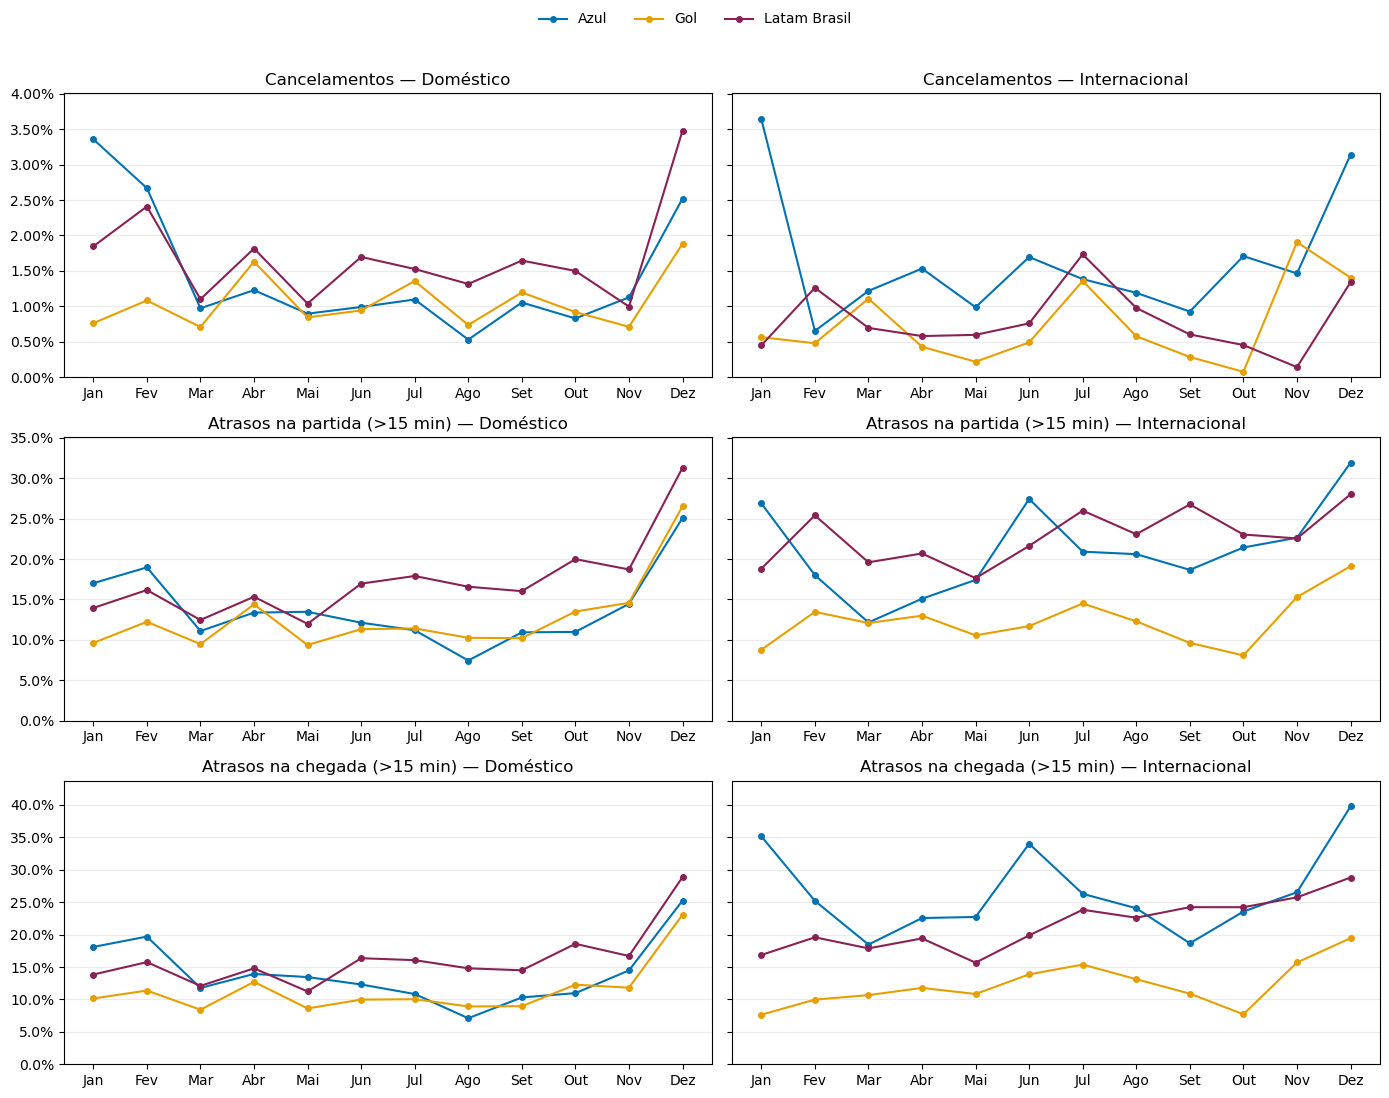

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

cores = {
    "Azul": "#0072B2",
    "Gol": "#E69F00",
    "Latam Brasil": "#882255"
}

meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

titulos = {
    "cancelamento (%)": "Cancelamentos",
    "atraso_partida (%)": "Atrasos na partida (>15 min)",
    "atraso_chegada (%)": "Atrasos na chegada (>15 min)"
}

fig, eixos = plt.subplots(
    3, 2, figsize=(14, 11), sharex=True, sharey="row"
)

for linha, (indicador, titulo) in enumerate(titulos.items()):
    for coluna, tipo in enumerate(["Doméstico", "Internacional"]):
        ax = eixos[linha, coluna]

        tabela = (
            resumo_mensal.xs(tipo, level="tipo_voo")[indicador]
            .unstack("companhia")
            .reindex(range(1, 13))
        )

        for companhia, cor in cores.items():
            ax.plot(
                tabela.index,
                tabela[companhia],
                label=companhia,
                color=cor,
                marker="o",
                markersize=4
            )

        ax.set_title(f"{titulo} — {tipo}")
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
        ax.grid(axis="y", alpha=0.25)
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(meses)
        ax.tick_params(axis="x", labelbottom=True)

    limite_superior = max(resumo_mensal[indicador].max() * 1.10, 1)
    eixos[linha, 0].set_ylim(0, limite_superior)

fig.legend(
    *eixos[0, 0].get_legend_handles_labels(),
    loc="upper center",
    ncol=3,
    frameon=False
)

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 12.1. Percentuais mensais de cancelamento

A tabela apresenta o percentual de cancelamentos por mês e companhia,
separando operações domésticas e internacionais. O cálculo considera os voos cancelados com partida prevista informada
em relação ao total de registros com partida prevista informada.

In [22]:
cancelamentos_mensais = (
    voos_analise.assign(
        previsto=voos_analise["Partida Prevista"].notna(),
        cancelado_com_previsao=(
            voos_analise["Situação Voo"].eq("CANCELADO")
            & voos_analise["Partida Prevista"].notna()
        )
    )
    .groupby(["tipo_voo", "mes_analise", "companhia"])[
        ["previsto", "cancelado_com_previsao"]
    ]
    .sum()
)

taxas_cancelamento = (
    cancelamentos_mensais["cancelado_com_previsao"]
    .div(cancelamentos_mensais["previsto"].replace(0, float("nan")))
    .mul(100)
    .unstack("companhia")
    .reindex(columns=["Azul", "Gol", "Latam Brasil"])
)

meses = {
    1: "Jan", 2: "Fev", 3: "Mar", 4: "Abr",
    5: "Mai", 6: "Jun", 7: "Jul", 8: "Ago",
    9: "Set", 10: "Out", 11: "Nov", 12: "Dez"
}

for tipo in ["Doméstico", "Internacional"]:
    tabela = (
        taxas_cancelamento
        .xs(tipo, level="tipo_voo")
        .reindex(range(1, 13))
        .rename(index=meses)
        .rename_axis("Mês")
    )

    display(
        tabela.style
        .format("{:.2f}%", decimal=",", na_rep="Sem dados")
        .set_caption(f"Cancelamentos mensais - {tipo}")
    )

companhia,Azul,Gol,Latam Brasil
Mês,,,
Jan,"3,36%","0,76%","1,85%"
Fev,"2,67%","1,08%","2,41%"
Mar,"0,97%","0,71%","1,10%"
Abr,"1,23%","1,63%","1,81%"
Mai,"0,89%","0,84%","1,04%"
Jun,"0,99%","0,94%","1,70%"
Jul,"1,09%","1,36%","1,53%"
Ago,"0,53%","0,73%","1,31%"
Set,"1,05%","1,19%","1,64%"


companhia,Azul,Gol,Latam Brasil
Mês,,,
Jan,"3,64%","0,56%","0,45%"
Fev,"0,65%","0,48%","1,26%"
Mar,"1,22%","1,11%","0,69%"
Abr,"1,53%","0,43%","0,58%"
Mai,"0,99%","0,21%","0,59%"
Jun,"1,69%","0,49%","0,76%"
Jul,"1,38%","1,36%","1,73%"
Ago,"1,19%","0,58%","0,98%"
Set,"0,92%","0,28%","0,60%"


* As taxas de cancelamento variaram entre as companhias ao longo de 2025.

- Nas operações domésticas, a Gol apresentou a menor taxa em oito meses,
  e a Azul, em quatro. Dezembro concentrou a maior taxa da Gol (1,88%)
  e da Latam Brasil (3,48%); a maior taxa da Azul ocorreu em janeiro (3,36%).
- Nas operações internacionais, a Gol apresentou a menor taxa em oito
  meses, e a Latam Brasil, em quatro. A Azul registrou sua maior taxa
  em janeiro (3,64%).

Esses resultados complementam a comparação anual e mostram que
o desempenho relativo das companhias pode mudar conforme o mês.
Os percentuais descrevem 2025 e não garantem o mesmo comportamento
em outros anos.

## 13. Comparação anual dos indicadores

Os totais dos 12 meses são somados por companhia e tipo de operação.
Em seguida, são calculados os percentuais anuais de cancelamento
e atraso, mantendo os denominadores definidos no passo 11.

Esse procedimento considera o volume de voos de cada mês.
Valores menores representam menor frequência de ocorrências
no indicador analisado.

In [23]:
resumo_anual = voos_analise.groupby(
    ["companhia", "tipo_voo"]
).agg(
    previstos=("previsto", "sum"),
    cancelados_previstos=("cancelado_previsto", "sum"),
    avaliados_partida=("atraso_partida", "count"),
    partidas_atrasadas=("atraso_partida", "sum"),
    avaliados_chegada=("atraso_chegada", "count"),
    chegadas_atrasadas=("atraso_chegada", "sum")
)

resumo_anual["cancelamento (%)"] = (
    resumo_anual["cancelados_previstos"]
    .div(resumo_anual["previstos"].replace(0, float("nan")))
    .mul(100)
)

for etapa in ["partida", "chegada"]:
    numerador = (
        "partidas_atrasadas"
        if etapa == "partida"
        else "chegadas_atrasadas"
    )

    resumo_anual[f"atraso_{etapa} (%)"] = (
        resumo_anual[numerador]
        .div(
            resumo_anual[f"avaliados_{etapa}"]
            .replace(0, float("nan"))
        )
        .mul(100)
    )

comparacao_anual = (
    resumo_anual[indicadores]
    .rename_axis(columns="indicador")
    .stack()
    .unstack("companhia")
    .reorder_levels(["tipo_voo", "indicador"])
    .sort_index()
)

display(comparacao_anual.style.format("{:.2f}", decimal=","))

## 14. Conclusões e limitações

### Desempenho anual

A Gol apresentou os menores percentuais anuais de cancelamento e atraso
entre as três companhias, tanto nas operações domésticas quanto nas
internacionais.

Nos voos domésticos, a taxa de cancelamento foi de 1,07% na Gol,
1,45% na Azul e 1,70% na Latam Brasil. Entre as chegadas avaliadas,
os atrasos superiores a 15 minutos corresponderam a 11,49%, 13,98%
e 16,22%, respectivamente.

Nos voos internacionais, a Gol registrou 0,73% de cancelamentos e
12,20% de atrasos na chegada. A Latam Brasil apresentou 0,80% e 21,63%,
enquanto a Azul apresentou 1,65% e 26,55%.

### Variação mensal

Dezembro apresentou os maiores percentuais de atraso na partida e na
chegada das operações domésticas das três companhias. Nos voos
internacionais, a Gol apresentou a menor taxa de atraso na chegada
em todos os meses de 2025.

Nos cancelamentos domésticos, a Gol apresentou a menor taxa em oito
meses, e a Azul, em quatro. A maior taxa da Azul ocorreu em janeiro
(3,36%), enquanto Gol e Latam Brasil registraram seus maiores
percentuais em dezembro: 1,88% e 3,48%, respectivamente.

Nos cancelamentos internacionais, a Gol apresentou a menor taxa em
oito meses, e a Latam Brasil, em quatro.

Assim, o melhor desempenho anual não significa a menor taxa em todos
os meses. A comparação mensal complementa o panorama anual e ajuda
a contextualizar a escolha do passageiro.

Esses resultados descrevem a variação observada em 2025, mas não
permitem determinar suas causas nem confirmar um padrão que se
repita em outros anos.

### Qualidade dos dados

Não foram encontradas duplicatas exatas no recorte analisado.
A conversão dos horários preenchidos ocorreu sem falhas de formato,
e não foram identificadas chegadas anteriores às respectivas partidas
entre os registros com horários disponíveis.

A conferência identificou 24 registros com partidas previstas em meses
diferentes dos arquivos de origem, dentro de 2025, e um registro previsto
para 01/01/2026, excluído do recorte.

O ano e o mês de análise são definidos pela partida prevista ou,
quando ausente, pela partida real. Quando ambas estão ausentes,
mantém-se o mês do arquivo de 2025.

Também foram sinalizados 65 registros com diferenças extremas de horário.
A análise de sensibilidade apresentou alterações de até aproximadamente
0,013 ponto percentual nas taxas anuais de atraso, sem modificar a ordem
das companhias em cada operação e etapa avaliada.

Os registros foram mantidos conforme a fonte. Essa comparação não
comprova a precisão dos horários nem avalia a influência desses casos
em cada mês. O detalhamento está disponível no Apêndice A.

### Aplicação para o cliente

Considerando os indicadores agregados de 2025, a Gol apresentou
o desempenho mais favorável no recorte analisado.

A análise mensal mostra, entretanto, que outras companhias apresentaram
menores taxas de cancelamento em determinados meses.

Para uma viagem específica, a escolha também deve considerar a rota,
o aeroporto, o horário e o mês da viagem, pois os resultados gerais
podem diferir do desempenho de uma operação específica.

### Limitações

- A comparação não controla diferenças de rotas, aeroportos, horários
  ou condições operacionais entre as companhias.
- Os percentuais representam etapas de voo, e não passageiros afetados
  ou viagens completas com conexões.
- Um mesmo voo pode apresentar atraso na partida e na chegada.
  Esses indicadores são avaliados separadamente e suas contagens
  não devem ser somadas como se representassem voos distintos.
- Os voos realizados sem horários suficientes permanecem nos totais,
  mas ficam fora do cálculo da respectiva taxa de atraso.
  Esses registros não são classificados como pontuais.
- A taxa de cancelamento considera os cancelamentos com partida
  prevista informada em relação ao total de registros com essa
  informação. As taxas de atraso consideram os voos realizados
  com os horários necessários para avaliar cada etapa.
- Os percentuais anuais são calculados pelos totais do ano,
  e não pela média simples dos percentuais mensais.
- A coluna de justificativa está vazia no recorte, impedindo
  a identificação das causas por esse campo.
- A classificação de atraso adota diferença superior a 15 minutos.
- As verificações de qualidade não garantem a precisão de todos
  os dados informados na fonte.
- Os resultados representam os registros analisados de 2025
  e não garantem o desempenho de viagens futuras.

## Apêndice A - Detalhamento dos casos extremos

São apresentados os registros sinalizados na conferência do item 8.1,
ordenados pela diferença entre a partida real e a prevista.

A sinalização utiliza limites exploratórios de antecipação superior
a uma hora ou atraso superior a 24 horas, na partida ou na chegada.
Esses limites não substituem o critério de atraso superior a 15 minutos
e não determinam a exclusão dos registros.

In [24]:
with pd.option_context("display.max_rows", None):
    display(
        voos_analise.loc[casos_extremos, colunas_inspecao]
        .sort_values("diferenca_partida_min")
    )

,companhia,tipo_voo,Número Voo,Sigla ICAO Aeroporto Origem,Sigla ICAO Aeroporto Destino,Partida Prevista,Partida Real,diferenca_partida_min,Chegada Prevista,Chegada Real,diferenca_chegada_min
360162,Azul,Doméstico,2612,SBCF,SBPV,2025-05-31 21:15:00,2025-05-29 21:06:00,-2889.0,2025-06-01 00:50:00,2025-05-30 00:06:00,-2924.0
112897,Azul,Internacional,8709,KMCO,SBKP,2025-02-22 00:00:00,2025-02-21 00:28:00,-1412.0,2025-02-22 08:35:00,2025-02-21 08:53:00,-1422.0
179674,Azul,Internacional,Z8709,KMCO,SBKP,2025-03-09 23:30:00,2025-03-09 00:06:00,-1404.0,2025-03-10 08:05:00,2025-03-09 08:48:00,-1397.0
231786,Latam Brasil,Internacional,Z8127,KMCO,SBGR,2025-03-09 23:20:00,2025-03-09 00:14:00,-1386.0,2025-03-10 07:55:00,2025-03-09 08:28:00,-1407.0
927687,Azul,Internacional,Z8787,TNCC,SBEG,2025-12-08 22:30:00,2025-12-07 23:46:00,-1364.0,2025-12-09 03:20:00,2025-12-08 03:58:00,-1402.0
355651,Azul,Internacional,Z8731,KMCO,SBCF,2025-05-25 23:30:00,2025-05-25 01:00:00,-1350.0,2025-05-26 08:20:00,2025-05-25 09:30:00,-1370.0
927685,Azul,Doméstico,Z8787,SBEG,SBCF,2025-12-09 04:20:00,2025-12-08 05:55:00,-1345.0,2025-12-09 08:00:00,2025-12-08 09:27:00,-1353.0
355147,Azul,Doméstico,4001,SBRF,SBGO,2025-05-25 22:00:00,2025-05-25 02:07:00,-1193.0,2025-05-26 00:45:00,2025-05-25 04:59:00,-1186.0
349574,Azul,Doméstico,5035,SBRF,SBSG,2025-05-18 23:00:00,2025-05-18 04:16:00,-1124.0,2025-05-19 00:05:00,2025-05-18 05:09:00,-1136.0
289042,Gol,Doméstico,1450,SBGR,SBGO,2025-04-11 23:20:00,2025-04-11 08:26:00,-894.0,2025-04-12 01:00:00,2025-04-11 09:51:00,-909.0


## Apêndice B - Gráficos para apresentação

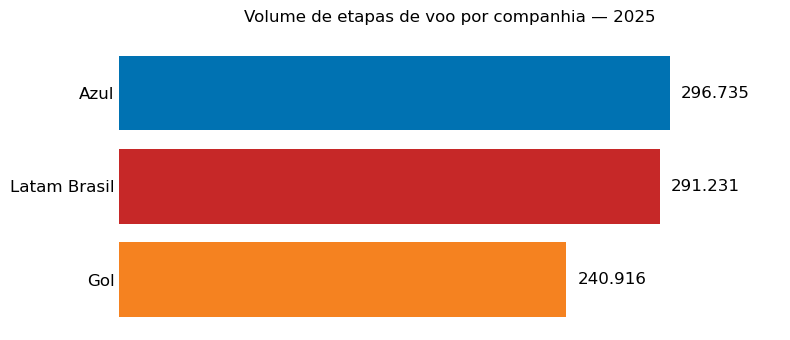

In [25]:
volume_companhias = (
    voos_analise.groupby("companhia")
    .size()
    .sort_values()
)

cores = {
    "Gol": "#F58220",
    "Azul": "#0072B2",
    "Latam Brasil": "#C62828"
}

fig, ax = plt.subplots(figsize=(8, 3.5))

barras = ax.barh(
    volume_companhias.index,
    volume_companhias.values,
    color=[cores[companhia] for companhia in volume_companhias.index]
)

ax.bar_label(
    barras,
    labels=[
        f"{valor:,.0f}".replace(",", ".")
        for valor in volume_companhias
    ],
    padding=8,
    fontsize=12
)

ax.set_title("Volume de etapas de voo por companhia — 2025", pad=15)
ax.set_xlim(0, volume_companhias.max() * 1.20)
ax.set_xticks([])
ax.tick_params(axis="y", length=0, labelsize=12)

for borda in ax.spines.values():
    borda.set_visible(False)

plt.tight_layout()
plt.savefig(
    "volume_voos_2025.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)
plt.show()

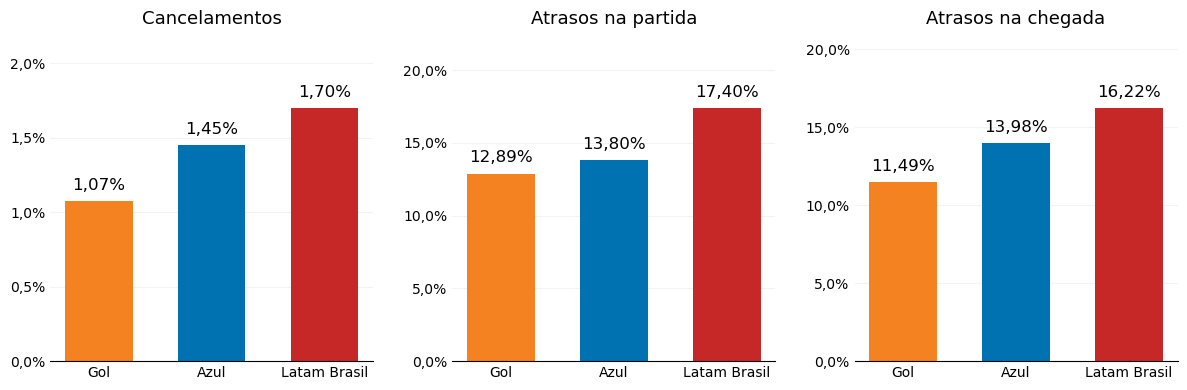

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter

companhias = ["Gol", "Azul", "Latam Brasil"]

cores = {
    "Gol": "#F58220",
    "Azul": "#0072B2",
    "Latam Brasil": "#C62828"
}

indicadores_grafico = {
    "cancelamento (%)": "Cancelamentos",
    "atraso_partida (%)": "Atrasos na partida",
    "atraso_chegada (%)": "Atrasos na chegada"
}

fig, eixos = plt.subplots(ncols=3, figsize=(12, 4))

for ax, (indicador, titulo) in zip(
    eixos, indicadores_grafico.items()
):
    valores = comparacao_anual.loc[
        ("Doméstico", indicador), companhias
    ].astype(float)

    barras = ax.bar(
        companhias,
        valores,
        color=[cores[companhia] for companhia in companhias],
        width=0.6
    )

    ax.bar_label(
        barras,
        labels=[
            f"{valor:.2f}%".replace(".", ",")
            for valor in valores
        ],
        padding=6,
        fontsize=12
    )

    ax.set_title(titulo, fontsize=13, pad=15)
    ax.set_ylim(0, valores.max() * 1.25)

    # Eixos com uma casa decimal, evitando rótulos repetidos
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_formatter(
        FuncFormatter(
            lambda valor, pos: f"{valor:.1f}%".replace(".", ",")
        )
    )

    ax.tick_params(axis="x", length=0, labelsize=10)
    ax.tick_params(axis="y", length=0, labelsize=10)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    for borda in ["top", "right", "left"]:
        ax.spines[borda].set_visible(False)

fig.tight_layout(w_pad=2)

fig.savefig(
    "desempenho_anual_domestico.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()

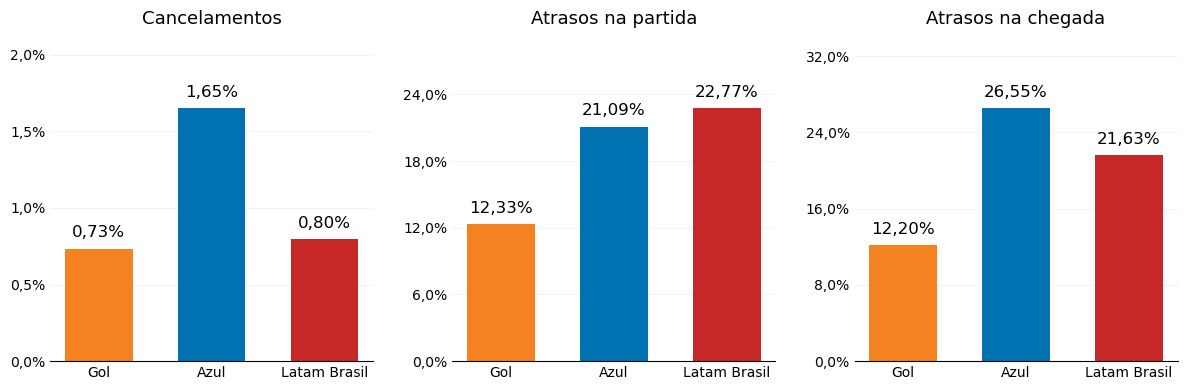

In [27]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter

companhias = ["Gol", "Azul", "Latam Brasil"]

cores = {
    "Gol": "#F58220",
    "Azul": "#0072B2",
    "Latam Brasil": "#C62828"
}

indicadores_grafico = {
    "cancelamento (%)": "Cancelamentos",
    "atraso_partida (%)": "Atrasos na partida",
    "atraso_chegada (%)": "Atrasos na chegada"
}

fig, eixos = plt.subplots(ncols=3, figsize=(12, 4))

for ax, (indicador, titulo) in zip(
    eixos, indicadores_grafico.items()
):
    valores = comparacao_anual.loc[
        ("Internacional", indicador), companhias
    ].astype(float)

    barras = ax.bar(
        companhias,
        valores,
        color=[cores[companhia] for companhia in companhias],
        width=0.6
    )

    ax.bar_label(
        barras,
        labels=[
            f"{valor:.2f}%".replace(".", ",")
            for valor in valores
        ],
        padding=6,
        fontsize=12
    )

    ax.set_title(titulo, fontsize=13, pad=15)
    ax.set_ylim(0, valores.max() * 1.25)

    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_formatter(
        FuncFormatter(
            lambda valor, pos: f"{valor:.1f}%".replace(".", ",")
        )
    )

    ax.tick_params(axis="x", length=0, labelsize=10)
    ax.tick_params(axis="y", length=0, labelsize=10)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    for borda in ["top", "right", "left"]:
        ax.spines[borda].set_visible(False)

fig.tight_layout(w_pad=2)

fig.savefig(
    "desempenho_anual_internacional.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()

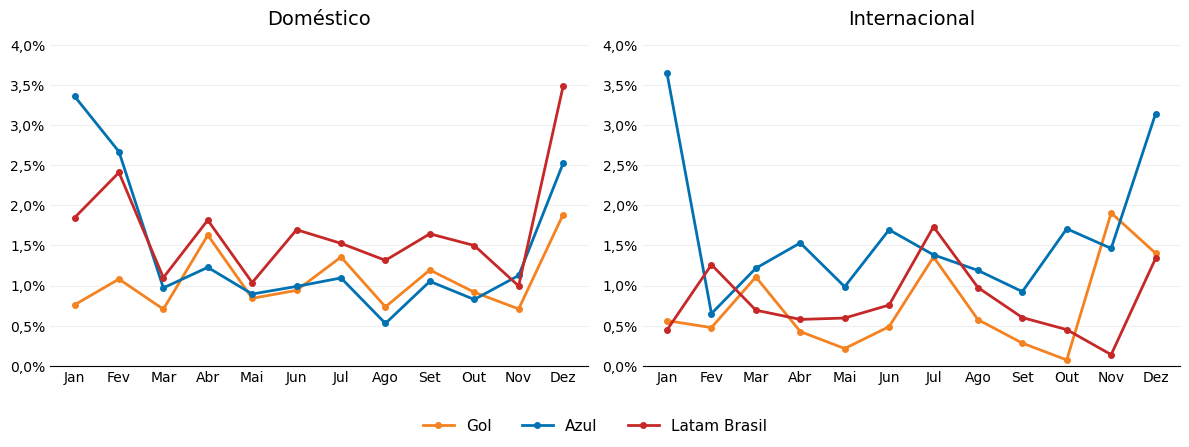

In [28]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter

companhias = ["Gol", "Azul", "Latam Brasil"]

cores = {
    "Gol": "#F58220",
    "Azul": "#0072B2",
    "Latam Brasil": "#C62828"
}

meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

fig, eixos = plt.subplots(
    ncols=2,
    figsize=(12, 4.5),
    sharey=True
)

limite_y = taxas_cancelamento[companhias].max().max() + 0.4

for ax, tipo in zip(eixos, ["Doméstico", "Internacional"]):
    tabela = (
        taxas_cancelamento
        .xs(tipo, level="tipo_voo")
        .reindex(range(1, 13))
    )

    for companhia in companhias:
        ax.plot(
            range(1, 13),
            tabela[companhia],
            label=companhia,
            color=cores[companhia],
            marker="o",
            linewidth=2,
            markersize=4
        )

    ax.set_title(tipo, fontsize=14, pad=12)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(meses, fontsize=10)
    ax.set_ylim(0, limite_y)

    ax.yaxis.set_major_locator(MultipleLocator(0.5))
    ax.yaxis.set_major_formatter(
        FuncFormatter(
            lambda valor, pos: f"{valor:.1f}%".replace(".", ",")
        )
    )

    ax.tick_params(axis="both", length=0)
    ax.tick_params(axis="y", labelleft=True)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    for borda in ["top", "right", "left"]:
        ax.spines[borda].set_visible(False)

legendas, nomes = eixos[0].get_legend_handles_labels()

fig.legend(
    legendas,
    nomes,
    loc="lower center",
    ncol=3,
    frameon=False,
    fontsize=11
)

fig.tight_layout(rect=[0, 0.10, 1, 1])

fig.savefig(
    "cancelamentos_mensais_2025.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()

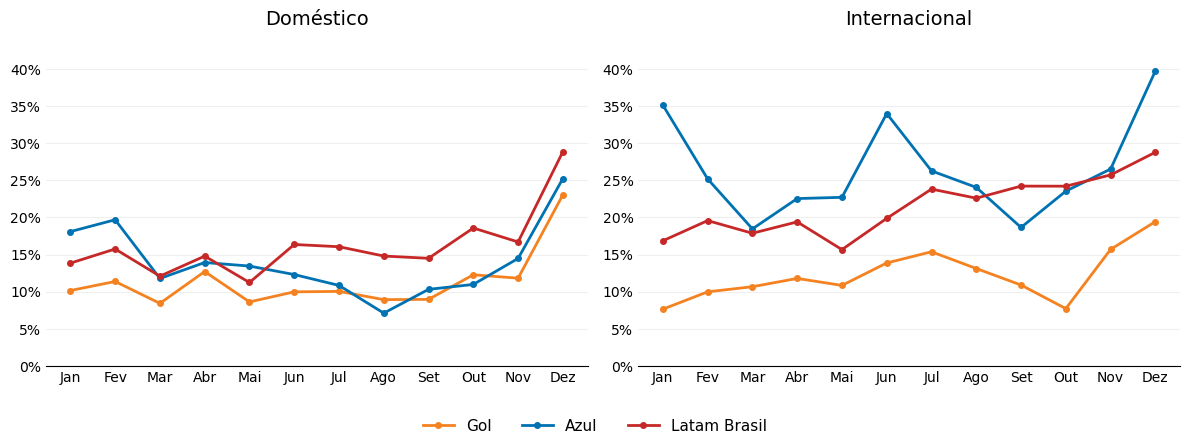

In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter

companhias = ["Gol", "Azul", "Latam Brasil"]

cores = {
    "Gol": "#F58220",
    "Azul": "#0072B2",
    "Latam Brasil": "#C62828"
}

meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

avaliaveis = (
    voos_analise["Situação Voo"].eq("REALIZADO")
    & voos_analise["Chegada Prevista"].notna()
    & voos_analise["Chegada Real"].notna()
)

taxas_chegada_mensais = (
    voos_analise.loc[avaliaveis]
    .assign(
        atraso_chegada=lambda tabela:
            tabela["diferenca_chegada_min"].gt(15)
    )
    .groupby(["tipo_voo", "mes_analise", "companhia"])[
        "atraso_chegada"
    ]
    .mean()
    .mul(100)
    .unstack("companhia")
    .reindex(columns=companhias)
)

fig, eixos = plt.subplots(
    ncols=2,
    figsize=(12, 4.5),
    sharey=True
)

limite_y = taxas_chegada_mensais.max().max() + 4

for ax, tipo in zip(eixos, ["Doméstico", "Internacional"]):
    tabela = (
        taxas_chegada_mensais
        .xs(tipo, level="tipo_voo")
        .reindex(range(1, 13))
    )

    for companhia in companhias:
        ax.plot(
            range(1, 13),
            tabela[companhia],
            label=companhia,
            color=cores[companhia],
            marker="o",
            linewidth=2,
            markersize=4
        )

    ax.set_title(tipo, fontsize=14, pad=12)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(meses, fontsize=10)
    ax.set_ylim(0, limite_y)

    ax.yaxis.set_major_locator(MultipleLocator(5))
    ax.yaxis.set_major_formatter(
        FuncFormatter(
            lambda valor, pos: f"{valor:.0f}%"
        )
    )

    ax.tick_params(axis="both", length=0)
    ax.tick_params(axis="y", labelleft=True)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    for borda in ["top", "right", "left"]:
        ax.spines[borda].set_visible(False)

legendas, nomes = eixos[0].get_legend_handles_labels()

fig.legend(
    legendas,
    nomes,
    loc="lower center",
    ncol=3,
    frameon=False,
    fontsize=11
)

fig.tight_layout(rect=[0, 0.10, 1, 1])

fig.savefig(
    "atrasos_chegada_mensais_2025.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()